# Image Object and Face Detection using YOLO & OpenCV

## Overview

This notebook explores image-based object detection and face detection using pretrained YOLO models and OpenCV.

The experiments involve loading an image, applying different detection models, visualizing predictions, and combining detection outputs.

The notebook is designed to support experimentation with different YOLO model variants rather than depending on a fixed set of models.

## Objectives

- Understand image-based object detection.
- Load and use pretrained YOLO models.
- Perform general object detection.
- Experiment with face detection models.
- Combine predictions from multiple detection models.
- Visualize detection results using OpenCV and Matplotlib.

## Experiments

1. Import required libraries.
2. Load pretrained detection models.
3. Read and display an input image.
4. Perform object detection.
5. Perform face detection.
6. Combine detection results.
7. Analyze observations and results.

## 1. Import Required Libraries

The following libraries will be used throughout this notebook:

- **OpenCV:** For image loading and image processing.
- **Ultralytics:** For loading YOLO models and performing inference.
- **Matplotlib:** For displaying and visualizing detection results.
- **Pathlib:** For handling file paths.

In [1]:
import cv2
import matplotlib.pyplot as plt

from pathlib import Path
from ultralytics import YOLO

## 2. Load Pretrained Models

YOLO models are used to perform object detection and face detection.

For this experiment, we will start with:

- `yolov8n.pt` — General object detection.
- `yolov8m-face.pt` — Face detection.

The models are loaded separately so that we can experiment with their predictions independently.

**Note:** These are the initial models for this experiment. Other compatible pretrained models can also be tested.

In [2]:
# General object detection model
model = YOLO("../yolov8n.pt")

# Face detection model
face_model = YOLO("../yolov8m-face.pt")

## 3. Load Input Image

We will use an example image stored in the `assets/demo-images/` directory.

OpenCV loads images in BGR color format rather than RGB.

We will also verify that the image was loaded successfully before proceeding.

In [7]:
image_path = Path("../assets/demo-images/demo2.jpg")

photo = cv2.imread(str(image_path))

if photo is None:
    raise FileNotFoundError(f"Unable to load image: {image_path}")

print("Image loaded successfully!")
print("Image dimensions:", photo.shape)

Image loaded successfully!
Image dimensions: (624, 936, 3)


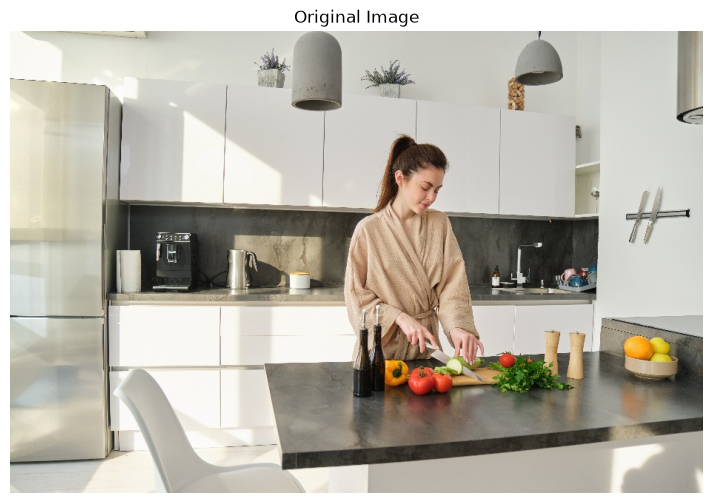

In [8]:
plt.figure(figsize=(10, 6))

plt.imshow(cv2.cvtColor(photo, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off");

## 4. General Object Detection

In this experiment, we pass the input image through the general YOLO model.

The model predicts supported object classes and generates bounding boxes around detected objects.

The predictions can include:

- Object class labels.
- Bounding box coordinates.
- Confidence scores.

In [9]:
object_results = model(photo)

object_detected = object_results[0].plot()


0: 448x640 1 person, 3 bottles, 1 cup, 1 bowl, 5 apples, 1 orange, 1 chair, 3 potted plants, 1 dining table, 1 refrigerator, 9.3ms
Speed: 2.2ms preprocess, 9.3ms inference, 1.3ms postprocess per image at shape (1, 3, 448, 640)


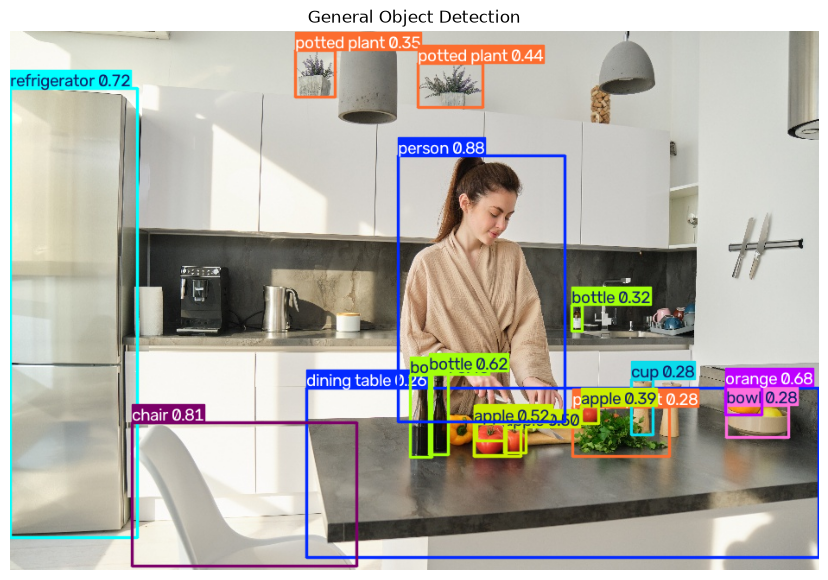

In [10]:
plt.figure(figsize=(12, 7))

plt.imshow(cv2.cvtColor(object_detected, cv2.COLOR_BGR2RGB))
plt.title("General Object Detection")
plt.axis("off");

## 5. Face Detection

Now we will use a dedicated YOLO-based face detection model.

The model is obtained from the open-source repository:

https://github.com/akanametov/yolo-face

Unlike general object detection, this model is specifically designed to detect human faces.

The model will process the same input image independently.

In [11]:
face_results = face_model(photo)

face_detected = face_results[0].plot()


0: 640x960 1 face, 19.4ms
Speed: 7.6ms preprocess, 19.4ms inference, 3.0ms postprocess per image at shape (1, 3, 640, 960)


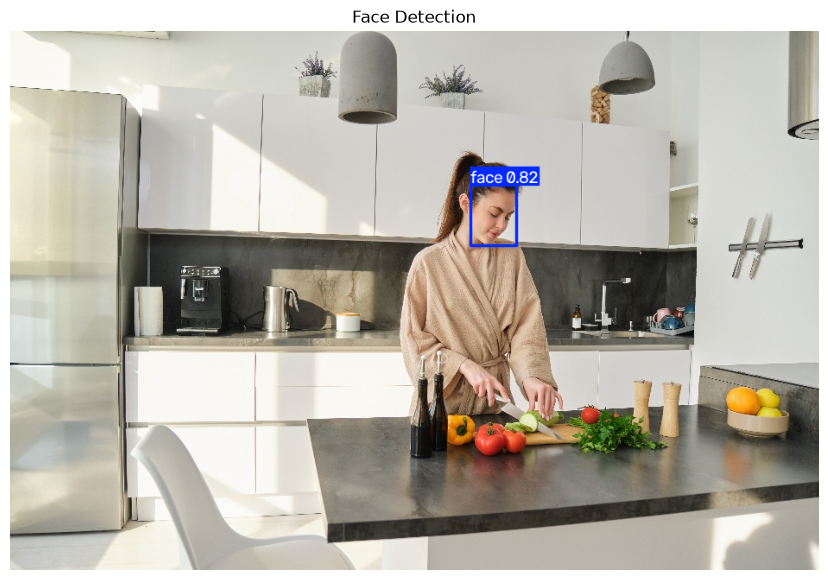

In [14]:
plt.figure(figsize=(12, 7))

plt.imshow(cv2.cvtColor(face_detected, cv2.COLOR_BGR2RGB))
plt.title("Face Detection")
plt.axis("off");

## 6. Combined Object and Face Detection

In this experiment, we combine the visual predictions of both detection models.

First, the general object detection model annotates the original image.

Next, the face detection model adds its annotations to the already annotated image.

This allows us to visualize the results of both detection tasks together.

**Important:** This combines the visual annotations, not the underlying model predictions into one unified detection model.

In [15]:
object_annotated = object_results[0].plot()

combined_result = face_results[0].plot(
    img=object_annotated
)

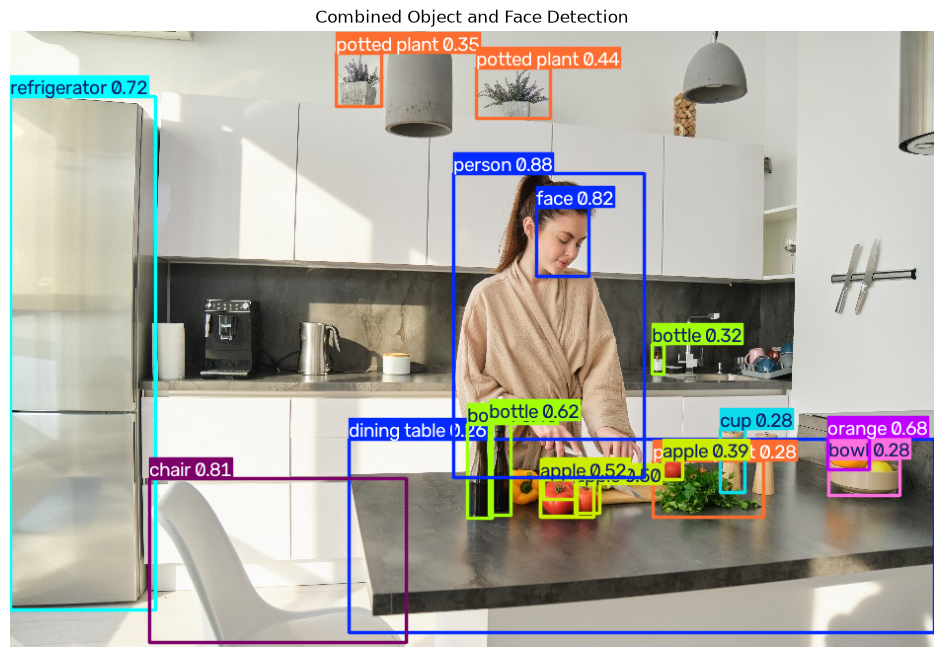

In [16]:
plt.figure(figsize=(14, 8))

plt.imshow(cv2.cvtColor(combined_result, cv2.COLOR_BGR2RGB))
plt.title("Combined Object and Face Detection")
plt.axis("off");

## 7. Observations

Record your actual observations after executing the experiments.

Things to examine:

- Which objects were successfully detected?
- How many faces were detected?
- Were any objects or faces missed?
- Did both models produce overlapping bounding boxes?
- How did the combined output look compared with individual outputs?

## 8. Conclusion

This experiment demonstrates how pretrained YOLO models can be used for general object detection and face detection on static images.

It also demonstrates how predictions from multiple models can be visually combined using OpenCV and Ultralytics.

## 9. Key Learnings

- Loading pretrained YOLO models.
- Reading images using OpenCV.
- Performing object and face detection.
- Visualizing bounding boxes and labels.
- Combining annotations from multiple models.
- Understanding the role of separate detection models.

## 10. References

- [Ultralytics YOLO](https://github.com/ultralytics/ultralytics)
- [YOLO Face by akanametov](https://github.com/akanametov/yolo-face)
- [OpenCV Documentation](https://docs.opencv.org/)

## 11. Understanding Detection Results

YOLO returns prediction results containing information about detected objects.

Each detection can include:

- Bounding box coordinates.
- Class ID.
- Class name.
- Confidence score.

We can access this information through the Results object returned by the YOLO model.

In [17]:
object_result = object_results[0]

print("Detected Objects:")

for box in object_result.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    class_name = object_result.names[class_id]

    print(
        f"Class: {class_name} | "
        f"Confidence: {confidence:.2f}"
    )

Detected Objects:
Class: person | Confidence: 0.88
Class: chair | Confidence: 0.81
Class: refrigerator | Confidence: 0.72
Class: orange | Confidence: 0.68
Class: bottle | Confidence: 0.62
Class: apple | Confidence: 0.52
Class: apple | Confidence: 0.50
Class: bottle | Confidence: 0.45
Class: potted plant | Confidence: 0.44
Class: apple | Confidence: 0.39
Class: apple | Confidence: 0.36
Class: potted plant | Confidence: 0.35
Class: apple | Confidence: 0.33
Class: bottle | Confidence: 0.32
Class: bowl | Confidence: 0.28
Class: cup | Confidence: 0.28
Class: potted plant | Confidence: 0.28
Class: dining table | Confidence: 0.26


- **`boxes`**: Contains the detected bounding boxes.
- **`cls`**: Contains the predicted class IDs.
- **`conf`**: Contains the confidence scores.
- **`names`**: Maps class IDs to their corresponding readable class names.

## 12. Face Detection Analysis

We will now inspect the predictions returned by the face detection model.

This helps us understand how many faces were detected and the confidence associated with each prediction.


In [18]:
face_result = face_results[0]

print("Detected Faces:", len(face_result.boxes))

for index, box in enumerate(face_result.boxes, start=1):
    confidence = float(box.conf[0])

    print(
        f"Face {index} | "
        f"Confidence: {confidence:.2f}"
    )

Detected Faces: 1
Face 1 | Confidence: 0.82


## 13. Detection Summary

Let's summarize the predictions generated by both models.

In [19]:
object_count = len(object_results[0].boxes)
face_count = len(face_results[0].boxes)

print("Detection Summary")
print("-" * 30)
print("Total objects detected:", object_count)
print("Total faces detected:", face_count)

Detection Summary
------------------------------
Total objects detected: 18
Total faces detected: 1


## 14. Save Detection Results

We will save the combined detection output in the assets directory.

This allows us to reuse the generated result without running model inference again.

In [20]:
output_path = Path("../assets/screenshots/combined-detection.png")

output_path.parent.mkdir(parents=True, exist_ok=True)

success = cv2.imwrite(str(output_path), combined_result)

if success:
    print("Detection output saved:", output_path)
else:
    print("Failed to save detection output.")

Detection output saved: ..\assets\screenshots\combined-detection.png
